In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [3]:
import json
import time

import matplotlib.pyplot as plt
import torch
from torch import nn, optim

from data_loader import get_dataloaders
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed

SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001
LATENT_DIM = 100

DEVICE = get_device()

set_seed(SEED)
ensure_results_dirs()

print(f"Device: {DEVICE}")


Device: xpu


In [4]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE)

print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches:    {len(test_loader)}")

images, labels = next(iter(train_loader))

print(f"\nImage shape: {images.shape}")
print(f"Pixel range: [{images.min().item():.4f}, {images.max().item():.4f}]")


Training batches:   438
Validation batches: 55
Testing batches:    55

Image shape: torch.Size([128, 1, 28, 28])
Pixel range: [0.0000, 1.0000]


In [5]:
from models.dcgan import (
    build_dcgan_discriminator,
    build_dcgan_generator,
)

generator = build_dcgan_generator(latent_dim=LATENT_DIM).to(DEVICE)

discriminator = build_dcgan_discriminator().to(DEVICE)

print("Generator:")
print(generator)

print("\nDiscriminator:")
print(discriminator)

Generator:
Sequential(
  (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
  (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU(inplace=True)
  (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (7): Tanh()
)

Discriminator:
Sequential(
  (0): Conv2d(1, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (1): LeakyReLU(negative_slope=0.2, inplace=True)
  (2): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (4): LeakyReLU(negative_slope=0.2, inplace=True)
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linea

In [6]:
noise = torch.randn(
    BATCH_SIZE,
    LATENT_DIM,
    1,
    1,
    device=DEVICE,
)

with torch.no_grad():
    fake_images = generator(noise)
    discriminator_output = discriminator(fake_images)

print(f"Noise shape: {noise.shape}")
print(f"Generated images shape: {fake_images.shape}")
print(
    f"Generated pixel range: "
    f"[{fake_images.min().item():.4f}, {fake_images.max().item():.4f}]"
)
print(f"Discriminator output shape: {discriminator_output.shape}")


Noise shape: torch.Size([128, 100, 1, 1])
Generated images shape: torch.Size([128, 1, 28, 28])
Generated pixel range: [-1.0000, 1.0000]
Discriminator output shape: torch.Size([128, 1])


In [7]:
criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999),
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999),
)

real_label = 1.0
fake_label = 0.0


In [8]:
history = {
    "generator_loss": [],
    "discriminator_loss": [],
}

start_time = time.time()

for epoch in range(EPOCHS):
    generator.train()
    discriminator.train()

    total_g_loss = 0.0
    total_d_loss = 0.0
    total_samples = 0

    for real_images, _ in train_loader:
        real_images = real_images.to(DEVICE)
        real_images = real_images * 2 - 1

        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, 1, device=DEVICE)
        fake_targets = torch.zeros(batch_size, 1, device=DEVICE)

        # Train Discriminator
        optimizer_D.zero_grad()

        real_outputs = discriminator(real_images)
        d_real_loss = criterion(real_outputs, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
        fake_images = generator(noise)

        fake_outputs = discriminator(fake_images.detach())
        d_fake_loss = criterion(fake_outputs, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
        generated_images = generator(noise)

        generated_outputs = discriminator(generated_images)
        g_loss = criterion(generated_outputs, real_targets)

        g_loss.backward()
        optimizer_G.step()

        total_g_loss += g_loss.item() * batch_size
        total_d_loss += d_loss.item() * batch_size
        total_samples += batch_size

    avg_g_loss = total_g_loss / total_samples
    avg_d_loss = total_d_loss / total_samples

    history["generator_loss"].append(avg_g_loss)
    history["discriminator_loss"].append(avg_d_loss)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| G Loss: {avg_g_loss:.4f} "
        f"| D Loss: {avg_d_loss:.4f} "
        f"| Elapsed: {elapsed:.2f}s"
    )


Epoch [1/30] | G Loss: 3.1621 | D Loss: 0.9808 | Elapsed: 76.85s
Epoch [2/30] | G Loss: 1.4875 | D Loss: 1.1561 | Elapsed: 138.23s
Epoch [3/30] | G Loss: 1.3643 | D Loss: 1.1643 | Elapsed: 194.32s
Epoch [4/30] | G Loss: 1.6080 | D Loss: 1.0548 | Elapsed: 258.46s
Epoch [5/30] | G Loss: 1.6750 | D Loss: 1.0096 | Elapsed: 321.12s
Epoch [6/30] | G Loss: 1.6498 | D Loss: 0.9891 | Elapsed: 385.37s
Epoch [7/30] | G Loss: 1.7534 | D Loss: 0.9259 | Elapsed: 452.78s
Epoch [8/30] | G Loss: 1.7174 | D Loss: 0.9605 | Elapsed: 521.18s
Epoch [9/30] | G Loss: 1.6867 | D Loss: 0.9322 | Elapsed: 587.52s
Epoch [10/30] | G Loss: 1.7310 | D Loss: 0.9327 | Elapsed: 651.65s
Epoch [11/30] | G Loss: 1.7588 | D Loss: 0.9359 | Elapsed: 716.72s
Epoch [12/30] | G Loss: 1.7133 | D Loss: 0.9319 | Elapsed: 782.59s
Epoch [13/30] | G Loss: 1.7891 | D Loss: 0.9250 | Elapsed: 848.38s
Epoch [14/30] | G Loss: 1.7561 | D Loss: 0.9300 | Elapsed: 913.09s
Epoch [15/30] | G Loss: 1.7738 | D Loss: 0.9105 | Elapsed: 977.15s
Epoch

In [9]:
checkpoint = {
    "generator_state_dict": generator.state_dict(),
    "discriminator_state_dict": discriminator.state_dict(),
    "optimizer_G_state_dict": optimizer_G.state_dict(),
    "optimizer_D_state_dict": optimizer_D.state_dict(),
    "latent_dim": LATENT_DIM,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "history": history,
}

checkpoint_path = CHECKPOINT_DIR / "dcgan_final.pth"

torch.save(checkpoint, checkpoint_path)

print(f"Checkpoint saved: {checkpoint_path}")


Checkpoint saved: D:\Main\sem5\deep-learning\ASG_2\results\checkpoints\dcgan_final.pth


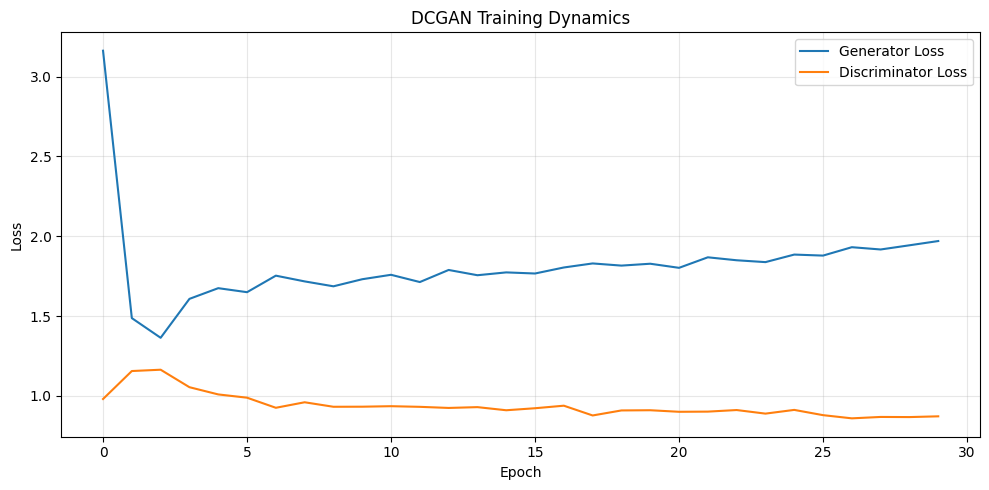

Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\dcgan_training_curves.png


In [10]:
plt.figure(figsize=(10, 5))

plt.plot(history["generator_loss"], label="Generator Loss")
plt.plot(history["discriminator_loss"], label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Dynamics")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "dcgan_training_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved: {figure_path}")


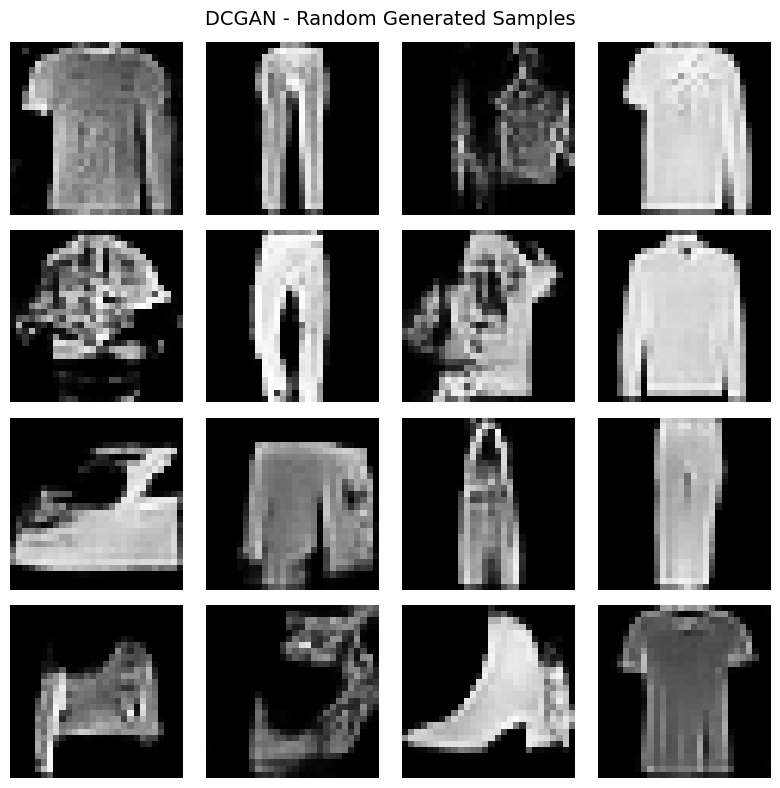

Generated samples shape: torch.Size([16, 1, 28, 28])
Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\dcgan_random_samples.png


In [11]:
generator.eval()

NUM_SAMPLES = 16

with torch.no_grad():
    noise = torch.randn(
        NUM_SAMPLES,
        LATENT_DIM,
        1,
        1,
        device=DEVICE,
    )

    generated_images = generator(noise)

    # Convert pixel range from [-1, 1] to [0, 1]
    generated_images = (generated_images + 1) / 2
    generated_images = generated_images.clamp(0, 1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for idx, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[idx].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

plt.suptitle("DCGAN - Random Generated Samples", fontsize=14)
plt.tight_layout()

figure_path = FIGURES_DIR / "dcgan_random_samples.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Generated samples shape: {generated_images.shape}")
print(f"Figure saved: {figure_path}")


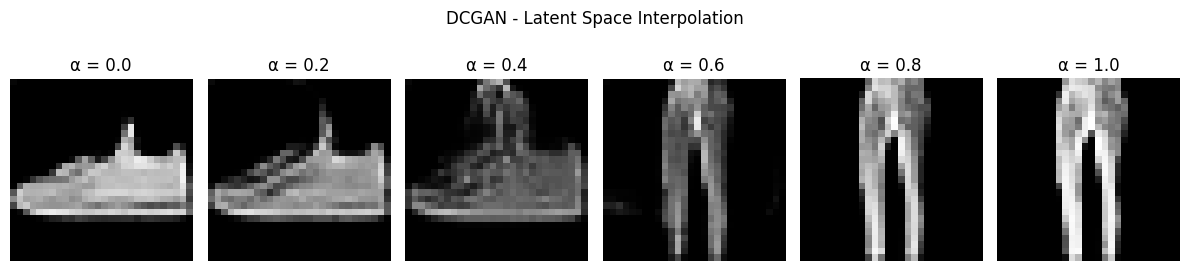

Interpolation samples: 6
Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\dcgan_interpolation.png


In [12]:
generator.eval()

z_a = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)
z_b = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)

alphas = torch.linspace(0, 1, 6, device=DEVICE)

interpolated_images = []

with torch.no_grad():
    for alpha in alphas:
        z_interpolated = (1 - alpha) * z_a + alpha * z_b

        generated = generator(z_interpolated)

        generated = (generated + 1) / 2
        generated = generated.clamp(0, 1)

        interpolated_images.append(generated.squeeze().cpu())

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for idx, ax in enumerate(axes):
    ax.imshow(
        interpolated_images[idx].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"α = {alphas[idx].item():.1f}")
    ax.axis("off")

plt.suptitle("DCGAN - Latent Space Interpolation")
plt.tight_layout()

figure_path = FIGURES_DIR / "dcgan_interpolation.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Interpolation samples: {len(interpolated_images)}")
print(f"Figure saved: {figure_path}")
